In [1]:
import os
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using:", DEVICE)

Using: cpu


In [4]:
CSV_PATH = r"C:\Users\prata\OneDrive\Desktop\AIOps Workload Forecaster\data\raw\cluster_metrics_18h.csv"

df = pd.read_csv(CSV_PATH)

df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2160, 11)


,timestamp,sys-mem-total,sys-mem-free,sys-interrupt-rate,sys-context-switch-rate,disk-io-time,cpu-user,cpu-system,load1m,load5m,load15m
0,2026-11-11 11:29:04.731860,1.717987e+10,1.311246e+10,2496.0920,4134.2100,0.189404,0.331456,0.094702,0.473509,0.473509,0.473509
1,2026-11-11 11:29:34.731877,1.717987e+10,1.317880e+10,2677.3215,4180.2650,0.186314,0.326050,0.093157,0.465785,0.469647,0.469647
2,2026-11-11 11:30:04.731884,1.717987e+10,1.253752e+10,2967.2002,4406.8516,0.216176,0.378308,0.108088,0.540441,0.493245,0.493245
3,2026-11-11 11:30:34.731887,1.717987e+10,1.241359e+10,2461.4090,3936.4297,0.221947,0.388408,0.110974,0.554868,0.508651,0.508651
4,2026-11-11 11:31:04.731891,1.717987e+10,1.283578e+10,2508.7537,3683.8083,0.202288,0.354003,0.101144,0.505719,0.508064,0.508064


Sampling interval statistics:
count    2159.000000
mean       30.000005
std         0.000002
min        30.000002
25%        30.000003
50%        30.000005
75%        30.000006
max        30.000036
Name: timestamp, dtype: float64

Most common intervals:
timestamp
30.000003    968
30.000006    658
30.000005    383
30.000004     60
30.000007     25
30.000002     17
30.000009     12
30.000008     11
30.000012      5
30.000011      4
Name: count, dtype: int64


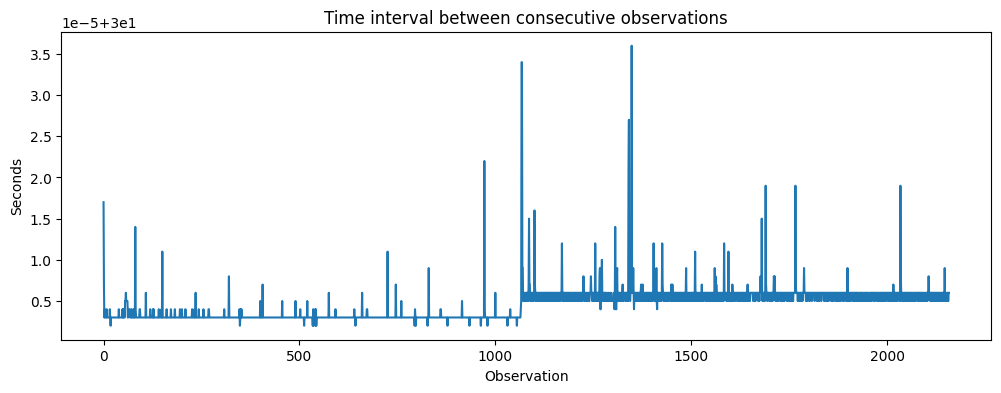

In [5]:
time_diff = df["timestamp"].diff().dropna().dt.total_seconds()

print("Sampling interval statistics:")
print(time_diff.describe())

print("\nMost common intervals:")
print(time_diff.value_counts().head(10))

plt.figure(figsize=(12, 4))
plt.plot(time_diff.values)
plt.title("Time interval between consecutive observations")
plt.xlabel("Observation")
plt.ylabel("Seconds")
plt.show()

In [6]:
features = [
    "sys-mem-free",
    "sys-interrupt-rate",
    "sys-context-switch-rate",
    "disk-io-time",
    "cpu-user",
    "cpu-system",
    "load1m",
    "load5m",
    "load15m"
]

data = df[features].copy()

print("Negative free-memory observations:",
      (data["sys-mem-free"] < 0).sum())

# Negative free memory is physically invalid.
# Replace these observations with missing values and interpolate.
data.loc[data["sys-mem-free"] < 0, "sys-mem-free"] = np.nan

data["sys-mem-free"] = (
    data["sys-mem-free"]
    .interpolate(method="linear")
    .ffill()
    .bfill()
)

# Check all selected features.
print("\nMissing values after cleaning:")
print(data.isna().sum())

assert not data.isna().any().any(), "Missing values remain in the dataset."

Negative free-memory observations: 21

Missing values after cleaning:
sys-mem-free               0
sys-interrupt-rate         0
sys-context-switch-rate    0
disk-io-time               0
cpu-user                   0
cpu-system                 0
load1m                     0
load5m                     0
load15m                    0
dtype: int64


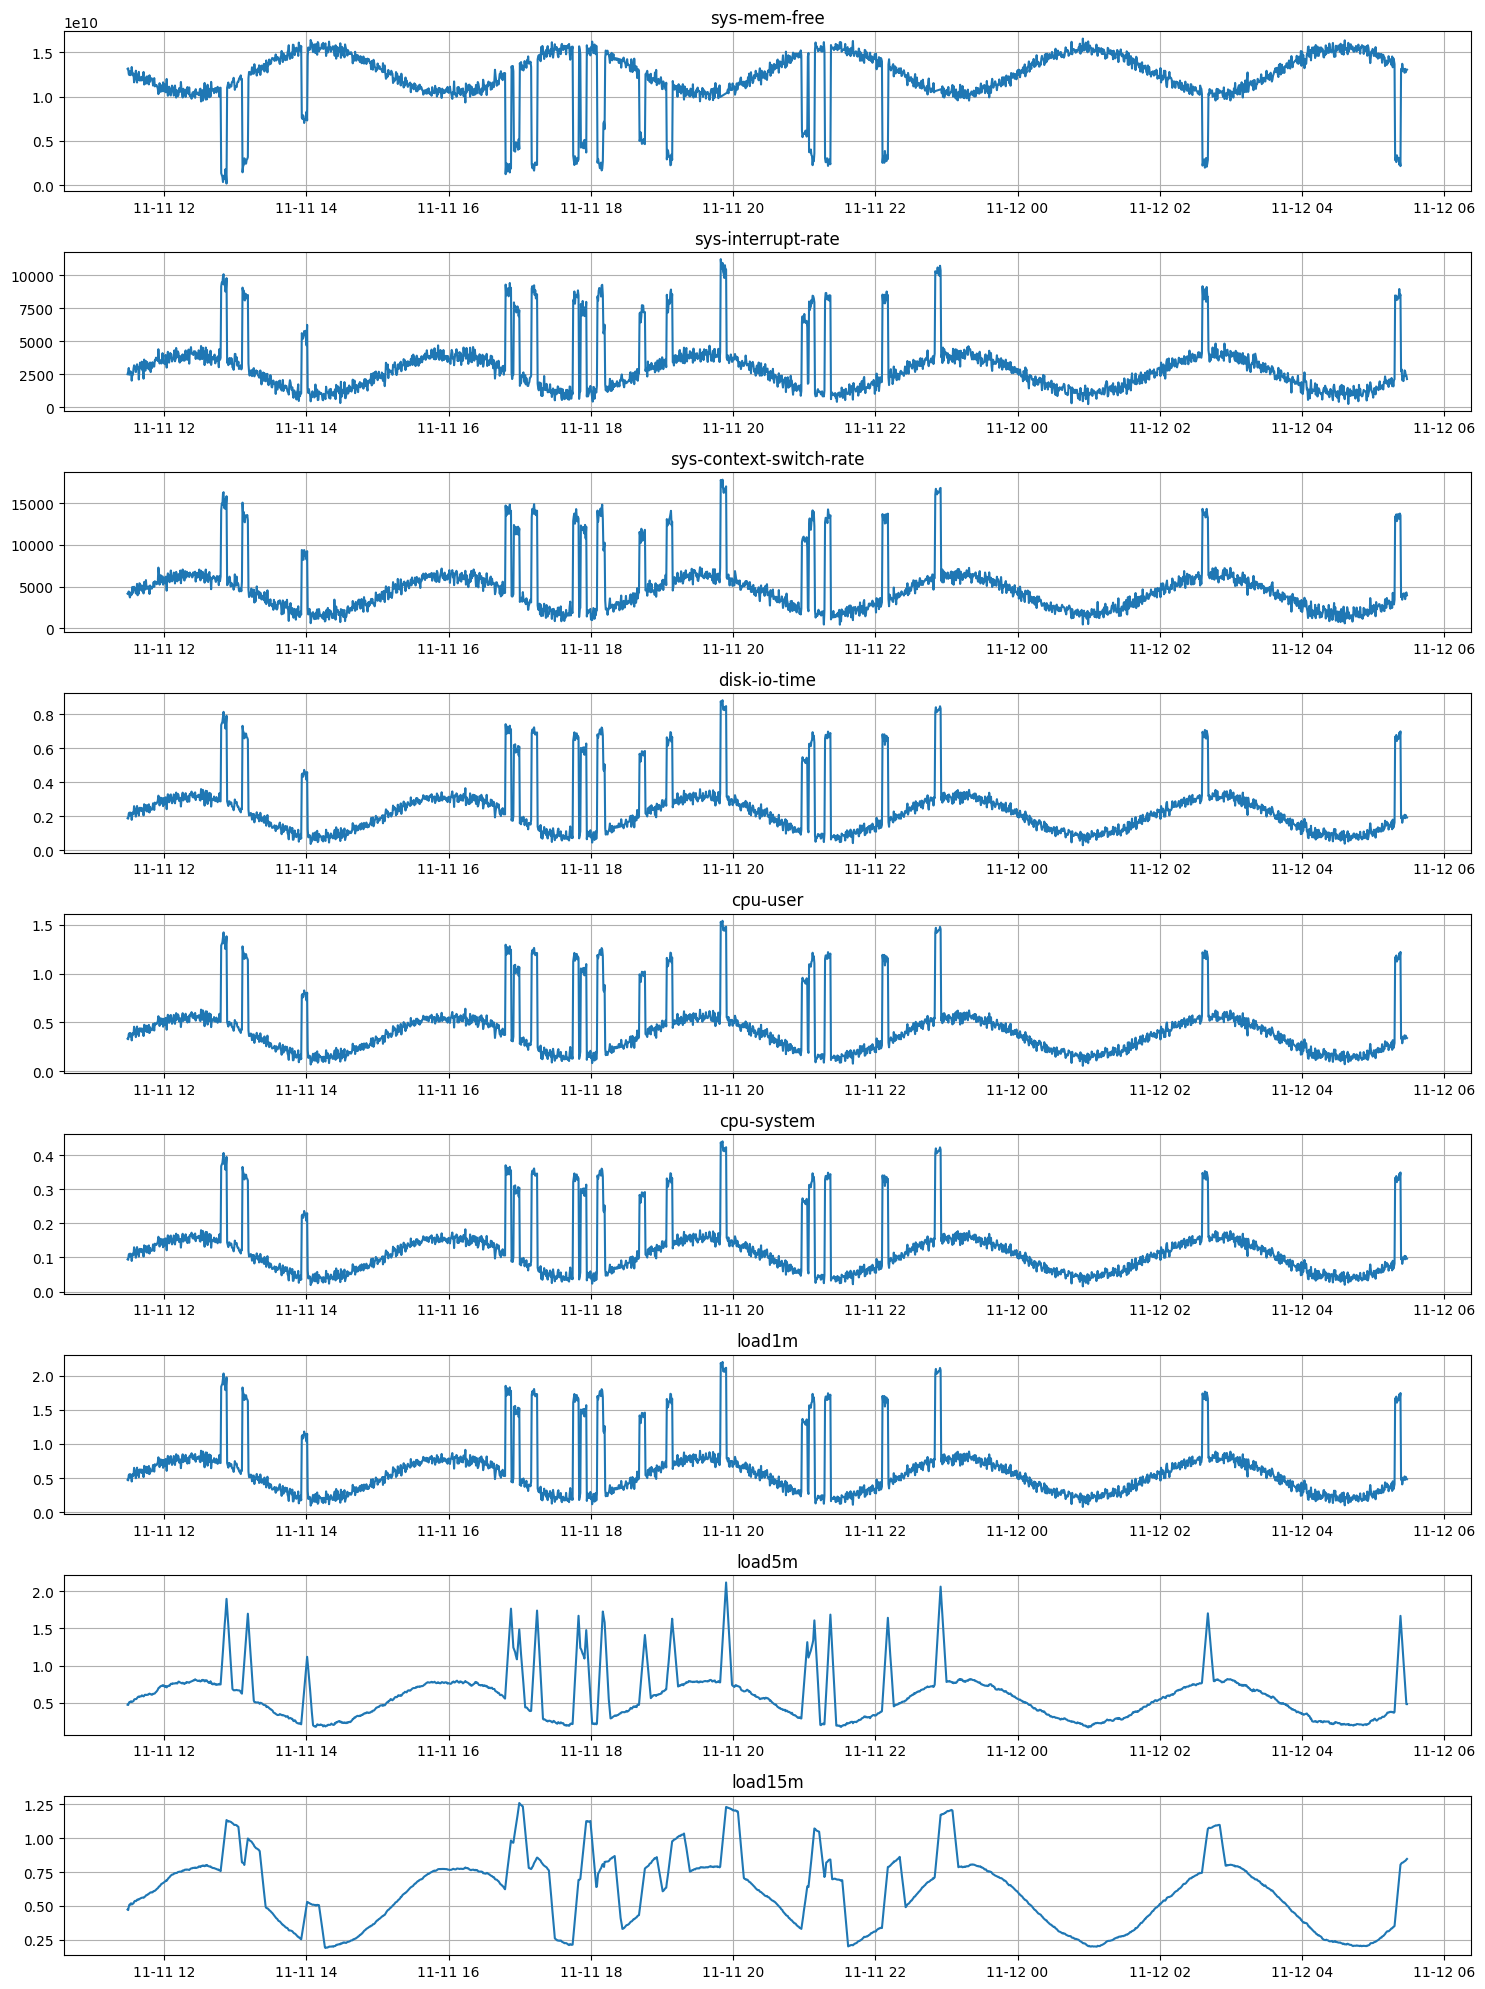

In [7]:
fig, axes = plt.subplots(len(features), 1, figsize=(15, 20))

for i, feature in enumerate(features):
    axes[i].plot(df["timestamp"], data[feature])
    axes[i].set_title(feature)
    axes[i].grid(True)

plt.tight_layout()
plt.show()

In [9]:
LOOKBACK = 48
HORIZON = 12

n = len(data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_raw = data.iloc[:train_end].copy()
val_raw = data.iloc[train_end:val_end].copy()
test_raw = data.iloc[val_end:].copy()

print("Train:", train_raw.shape)
print("Validation:", val_raw.shape)
print("Test:", test_raw.shape)

Train: (1512, 9)
Validation: (324, 9)
Test: (324, 9)


In [10]:
scaler = StandardScaler()

train_scaled = scaler.fit_transform(train_raw)
val_scaled = scaler.transform(val_raw)
test_scaled = scaler.transform(test_raw)

print("Number of features:", len(features))

Number of features: 9


In [11]:
class TimeSeriesDataset(Dataset):
    def __init__(self, values, lookback=48, horizon=12):
        self.values = torch.tensor(
            values, dtype=torch.float32
        )
        self.lookback = lookback
        self.horizon = horizon

    def __len__(self):
        return len(self.values) - self.lookback - self.horizon + 1

    def __getitem__(self, idx):
        x = self.values[idx : idx + self.lookback]

        y = self.values[
            idx + self.lookback :
            idx + self.lookback + self.horizon
        ]

        return x, y

In [12]:
BATCH_SIZE = 32

train_dataset = TimeSeriesDataset(
    train_scaled, LOOKBACK, HORIZON
)

val_dataset = TimeSeriesDataset(
    val_scaled, LOOKBACK, HORIZON
)

test_dataset = TimeSeriesDataset(
    test_scaled, LOOKBACK, HORIZON
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))
print("Testing windows:", len(test_dataset))

Training windows: 1453
Validation windows: 265
Testing windows: 265


In [13]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()

        position = torch.arange(max_len).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) *
            (-np.log(10000.0) / d_model)
        )

        pe = torch.zeros(max_len, d_model)

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer(
            "pe", pe.unsqueeze(0)
        )

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

In [14]:
class TransformerForecaster(nn.Module):
    def __init__(
        self,
        num_features,
        lookback,
        horizon,
        d_model=64,
        n_heads=4,
        num_layers=3,
        dropout=0.1
    ):
        super().__init__()

        self.input_projection = nn.Linear(
            num_features, d_model
        )

        self.positional_encoding = PositionalEncoding(
            d_model, max_len=lookback
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=128,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.norm = nn.LayerNorm(d_model)

        self.forecast_head = nn.Sequential(
            nn.Linear(d_model * lookback, 256),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(256, horizon * num_features)
        )

        self.lookback = lookback
        self.horizon = horizon
        self.num_features = num_features

    def forward(self, x):
        x = self.input_projection(x)

        x = self.positional_encoding(x)

        x = self.encoder(x)

        x = self.norm(x)

        x = x.reshape(x.size(0), -1)

        x = self.forecast_head(x)

        return x.reshape(
            -1, self.horizon, self.num_features
        )

In [15]:
NUM_FEATURES = len(features)

transformer_model = TransformerForecaster(
    num_features=NUM_FEATURES,
    lookback=LOOKBACK,
    horizon=HORIZON,
    d_model=64,
    n_heads=4,
    num_layers=3
).to(DEVICE)

print(transformer_model)

TransformerForecaster(
  (input_projection): Linear(in_features=9, out_features=64, bias=True)
  (positional_encoding): PositionalEncoding()
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (forecast_head): Sequential(
    (0): Linear(in_features=3072, out_features=256, bias=True)
   

In [16]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None

    model.train() if training else model.eval()

    total_loss = 0.0

    for x, y in loader:
        x = x.to(DEVICE)
        y = y.to(DEVICE)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            predictions = model(x)
            loss = criterion(predictions, y)

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )
                optimizer.step()

        total_loss += loss.item() * x.size(0)

    return total_loss / len(loader.dataset)

In [17]:
def train_forecaster(
    model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=1e-3,
    patience=8,
    save_path="best_model.pt"
):
    criterion = nn.MSELoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    best_val_loss = float("inf")
    best_state = None
    wait = 0

    history = {
        "train_loss": [],
        "val_loss": []
    }

    for epoch in range(epochs):
        train_loss = run_epoch(
            model, train_loader, criterion, optimizer
        )

        val_loss = run_epoch(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(
            f"Epoch {epoch + 1:03d}/{epochs} | "
            f"Train: {train_loss:.6f} | "
            f"Validation: {val_loss:.6f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            wait = 0

            torch.save(best_state, save_path)

        else:
            wait += 1

        if wait >= patience:
            print("Early stopping.")
            break

    model.load_state_dict(best_state)

    return model, history

In [18]:
transformer_model, transformer_history = train_forecaster(
    transformer_model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=1e-3,
    patience=8,
    save_path="transformer_best.pt"
)

Epoch 001/50 | Train: 0.823789 | Validation: 0.253069
Epoch 002/50 | Train: 0.579629 | Validation: 0.304868
Epoch 003/50 | Train: 0.494505 | Validation: 0.192131
Epoch 004/50 | Train: 0.469929 | Validation: 0.190518
Epoch 005/50 | Train: 0.440346 | Validation: 0.228429
Epoch 006/50 | Train: 0.415722 | Validation: 0.184768
Epoch 007/50 | Train: 0.408251 | Validation: 0.388373
Epoch 008/50 | Train: 0.404422 | Validation: 0.233033
Epoch 009/50 | Train: 0.383411 | Validation: 0.206294
Epoch 010/50 | Train: 0.372007 | Validation: 0.190307
Epoch 011/50 | Train: 0.349844 | Validation: 0.288724
Epoch 012/50 | Train: 0.354527 | Validation: 0.223899
Epoch 013/50 | Train: 0.343656 | Validation: 0.178159
Epoch 014/50 | Train: 0.338025 | Validation: 0.372272
Epoch 015/50 | Train: 0.309145 | Validation: 0.288876
Epoch 016/50 | Train: 0.295285 | Validation: 0.231775
Epoch 017/50 | Train: 0.263537 | Validation: 0.460961
Epoch 018/50 | Train: 0.266602 | Validation: 0.540352
Epoch 019/50 | Train: 0.2579

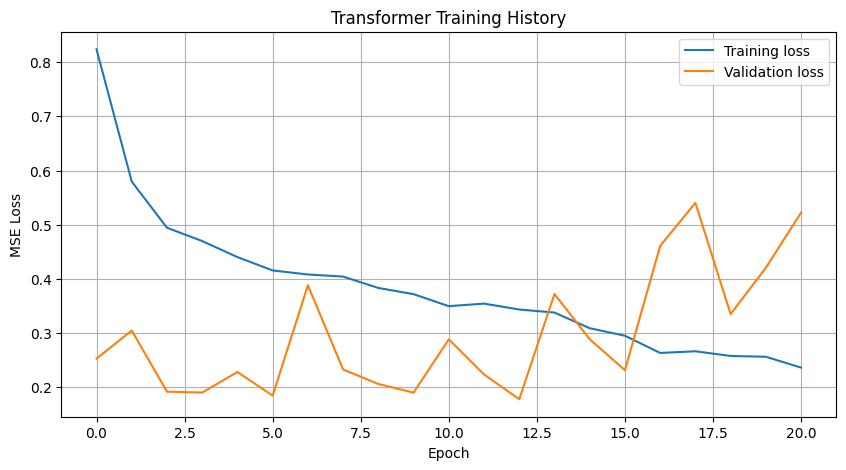

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(
    transformer_history["train_loss"],
    label="Training loss"
)

plt.plot(
    transformer_history["val_loss"],
    label="Validation loss"
)

plt.title("Transformer Training History")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
def get_predictions(model, loader):
    model.eval()

    predictions = []
    actuals = []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(DEVICE)

            pred = model(x)

            predictions.append(pred.cpu().numpy())
            actuals.append(y.numpy())

    return (
        np.concatenate(predictions, axis=0),
        np.concatenate(actuals, axis=0)
    )


def inverse_transform_3d(values, scaler):
    original_shape = values.shape

    values_2d = values.reshape(-1, original_shape[-1])

    restored = scaler.inverse_transform(values_2d)

    return restored.reshape(original_shape)


transformer_pred, transformer_actual = get_predictions(
    transformer_model, test_loader
)

transformer_pred_original = inverse_transform_3d(
    transformer_pred, scaler
)

transformer_actual_original = inverse_transform_3d(
    transformer_actual, scaler
)

In [21]:
def calculate_metrics(actual, predicted, feature_names):
    results = []

    for i, feature in enumerate(feature_names):
        y_true = actual[:, :, i].flatten()
        y_pred = predicted[:, :, i].flatten()

        mae = mean_absolute_error(y_true, y_pred)

        rmse = np.sqrt(
            mean_squared_error(y_true, y_pred)
        )

        nonzero = np.abs(y_true) > 1e-8

        mape = (
            np.mean(
                np.abs(
                    (y_true[nonzero] - y_pred[nonzero]) /
                    y_true[nonzero]
                )
            ) * 100
            if nonzero.any()
            else np.nan
        )

        results.append({
            "Feature": feature,
            "MAE": mae,
            "RMSE": rmse,
            "MAPE (%)": mape
        })

    return pd.DataFrame(results)


transformer_results = calculate_metrics(
    transformer_actual_original,
    transformer_pred_original,
    features
)

display(transformer_results)

,Feature,MAE,RMSE,MAPE (%)
0,sys-mem-free,1.248654e+09,2.127404e+09,17.398843
1,sys-interrupt-rate,7.692313e+02,1.279204e+03,48.920947
2,sys-context-switch-rate,1.270856e+03,2.057486e+03,50.467604
3,disk-io-time,6.001796e-02,1.006310e-01,43.160224
4,cpu-user,1.032530e-01,1.754638e-01,42.405742
5,cpu-system,2.964377e-02,5.015652e-02,42.518079
6,load1m,1.498335e-01,2.509083e-01,43.013692
7,load5m,8.213958e-02,1.419382e-01,21.355453
8,load15m,6.896440e-02,8.838858e-02,21.102387


In [ ]:
Bert Model Training.

In [22]:
PATCH_SIZE = 4

assert LOOKBACK % PATCH_SIZE == 0

NUM_PATCHES = LOOKBACK // PATCH_SIZE

def create_patches(x):
    batch_size = x.size(0)

    x = x.reshape(
        batch_size,
        NUM_PATCHES,
        PATCH_SIZE,
        NUM_FEATURES
    )

    return x.reshape(
        batch_size,
        NUM_PATCHES,
        PATCH_SIZE * NUM_FEATURES
    )

In [23]:
class TimeSeriesBERT(nn.Module):
    def __init__(
        self,
        num_features,
        lookback,
        horizon,
        patch_size=4,
        d_model=64,
        n_heads=4,
        num_layers=3,
        dropout=0.1
    ):
        super().__init__()

        self.num_features = num_features
        self.lookback = lookback
        self.horizon = horizon
        self.patch_size = patch_size

        self.num_patches = lookback // patch_size
        patch_dim = patch_size * num_features

        self.patch_embedding = nn.Linear(
            patch_dim, d_model
        )

        self.mask_token = nn.Parameter(
            torch.zeros(1, 1, d_model)
        )

        self.position_embedding = nn.Parameter(
            torch.zeros(1, self.num_patches, d_model)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=128,
            dropout=dropout,
            batch_first=True,
            activation="gelu"
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.norm = nn.LayerNorm(d_model)

        # Pretraining head: reconstruct original patches.
        self.reconstruction_head = nn.Linear(
            d_model, patch_dim
        )

        # Forecasting head: predict future telemetry.
        self.forecast_head = nn.Sequential(
            nn.Linear(d_model * self.num_patches, 256),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(
                256,
                horizon * num_features
            )
        )

        nn.init.normal_(self.position_embedding, std=0.02)
        nn.init.normal_(self.mask_token, std=0.02)

    def encode(self, patches, mask=None):
        x = self.patch_embedding(patches)

        if mask is not None:
            mask_token = self.mask_token.expand(
                x.size(0), x.size(1), -1
            )

            x = torch.where(
                mask.unsqueeze(-1),
                mask_token,
                x
            )

        x = x + self.position_embedding

        x = self.encoder(x)

        return self.norm(x)

    def reconstruct(self, patches, mask):
        encoded = self.encode(patches, mask)

        return self.reconstruction_head(encoded)

    def forward(self, x):
        patches = create_patches(x)

        encoded = self.encode(patches)

        encoded = encoded.reshape(
            encoded.size(0), -1
        )

        forecast = self.forecast_head(encoded)

        return forecast.reshape(
            -1, self.horizon, self.num_features
        )

In [24]:
bert_model = TimeSeriesBERT(
    num_features=NUM_FEATURES,
    lookback=LOOKBACK,
    horizon=HORIZON,
    patch_size=PATCH_SIZE,
    d_model=64,
    n_heads=4,
    num_layers=3
).to(DEVICE)

print(bert_model)

TimeSeriesBERT(
  (patch_embedding): Linear(in_features=36, out_features=64, bias=True)
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-2): 3 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (reconstruction_head): Linear(in_features=64, out_features=36, bias=True)
  (forecast_head): Sequential(
    (0): Linear(in_features=768, out_featur

In [25]:
def generate_patch_mask(batch_size, num_patches, mask_ratio=0.30):
    mask = torch.rand(
        batch_size, num_patches, device=DEVICE
    ) < mask_ratio

    # Ensure at least one masked patch per sample.
    for i in range(batch_size):
        if not mask[i].any():
            random_index = torch.randint(
                0, num_patches, (1,), device=DEVICE
            )
            mask[i, random_index] = True

    return mask

In [26]:
def pretrain_bert(
    model,
    train_loader,
    epochs=40,
    learning_rate=1e-3,
    mask_ratio=0.30,
    save_path="bert_pretrained.pt"
):
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=learning_rate,
        weight_decay=1e-4
    )

    criterion = nn.MSELoss()

    history = []

    for epoch in range(epochs):
        model.train()

        total_loss = 0.0
        total_samples = 0

        for x, _ in train_loader:
            x = x.to(DEVICE)

            patches = create_patches(x)

            mask = generate_patch_mask(
                x.size(0),
                NUM_PATCHES,
                mask_ratio
            )

            optimizer.zero_grad()

            reconstructed = model.reconstruct(
                patches, mask
            )

            # Calculate loss only on masked patches.
            loss = criterion(
                reconstructed[mask],
                patches[mask]
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )

            optimizer.step()

            total_loss += loss.item() * x.size(0)
            total_samples += x.size(0)

        epoch_loss = total_loss / total_samples
        history.append(epoch_loss)

        print(
            f"Pretraining Epoch {epoch + 1:03d}/{epochs} | "
            f"Masked Reconstruction Loss: {epoch_loss:.6f}"
        )

    torch.save(
        model.state_dict(),
        save_path
    )

    return model, history

In [27]:
bert_model, bert_pretrain_history = pretrain_bert(
    bert_model,
    train_loader,
    epochs=40,
    learning_rate=1e-3,
    mask_ratio=0.30,
    save_path="bert_pretrained.pt"
)

Pretraining Epoch 001/40 | Masked Reconstruction Loss: 0.835131
Pretraining Epoch 002/40 | Masked Reconstruction Loss: 0.750207
Pretraining Epoch 003/40 | Masked Reconstruction Loss: 0.763997
Pretraining Epoch 004/40 | Masked Reconstruction Loss: 0.769703
Pretraining Epoch 005/40 | Masked Reconstruction Loss: 0.723407
Pretraining Epoch 006/40 | Masked Reconstruction Loss: 0.713141
Pretraining Epoch 007/40 | Masked Reconstruction Loss: 0.687126
Pretraining Epoch 008/40 | Masked Reconstruction Loss: 0.653918
Pretraining Epoch 009/40 | Masked Reconstruction Loss: 0.676010
Pretraining Epoch 010/40 | Masked Reconstruction Loss: 0.604532
Pretraining Epoch 011/40 | Masked Reconstruction Loss: 0.525286
Pretraining Epoch 012/40 | Masked Reconstruction Loss: 0.512820
Pretraining Epoch 013/40 | Masked Reconstruction Loss: 0.485261
Pretraining Epoch 014/40 | Masked Reconstruction Loss: 0.453800
Pretraining Epoch 015/40 | Masked Reconstruction Loss: 0.408594
Pretraining Epoch 016/40 | Masked Recons

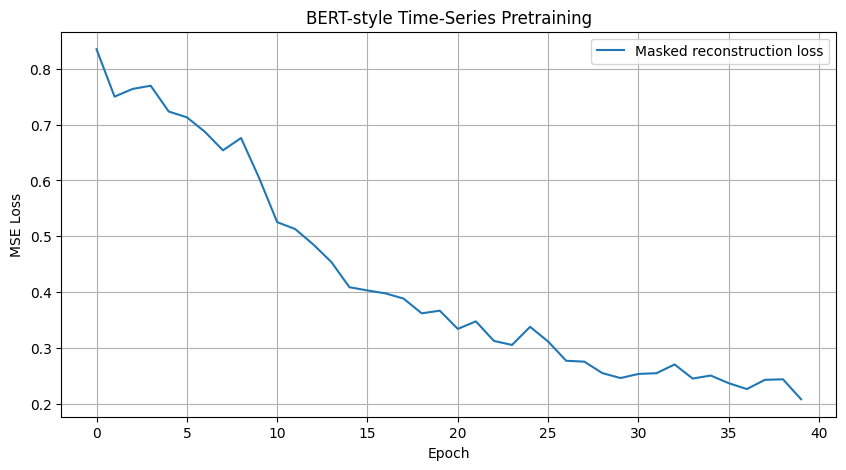

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(
    bert_pretrain_history,
    label="Masked reconstruction loss"
)

plt.title("BERT-style Time-Series Pretraining")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [29]:
bert_model, bert_history = train_forecaster(
    bert_model,
    train_loader,
    val_loader,
    epochs=50,
    learning_rate=5e-4,
    patience=8,
    save_path="bert_forecaster_best.pt"
)

Epoch 001/50 | Train: 0.721249 | Validation: 0.252827
Epoch 002/50 | Train: 0.524214 | Validation: 0.246686
Epoch 003/50 | Train: 0.483927 | Validation: 0.230240
Epoch 004/50 | Train: 0.449154 | Validation: 0.164780
Epoch 005/50 | Train: 0.429833 | Validation: 0.276155
Epoch 006/50 | Train: 0.420516 | Validation: 0.177992
Epoch 007/50 | Train: 0.403795 | Validation: 0.167862
Epoch 008/50 | Train: 0.402194 | Validation: 0.391486
Epoch 009/50 | Train: 0.387959 | Validation: 0.152471
Epoch 010/50 | Train: 0.374117 | Validation: 0.257183
Epoch 011/50 | Train: 0.360666 | Validation: 0.220439
Epoch 012/50 | Train: 0.360552 | Validation: 0.175204
Epoch 013/50 | Train: 0.345583 | Validation: 0.215051
Epoch 014/50 | Train: 0.341970 | Validation: 0.542126
Epoch 015/50 | Train: 0.346594 | Validation: 0.191778
Epoch 016/50 | Train: 0.325986 | Validation: 0.371007
Epoch 017/50 | Train: 0.311007 | Validation: 0.366853
Early stopping.


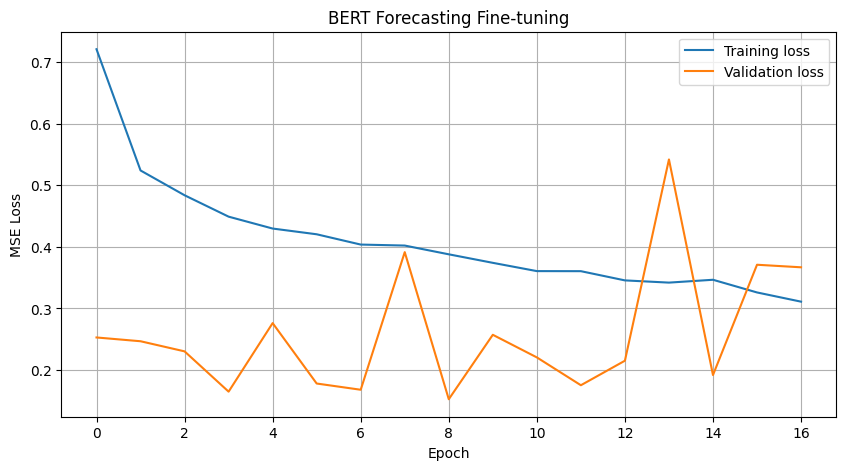

In [30]:
plt.figure(figsize=(10, 5))

plt.plot(
    bert_history["train_loss"],
    label="Training loss"
)

plt.plot(
    bert_history["val_loss"],
    label="Validation loss"
)

plt.title("BERT Forecasting Fine-tuning")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [31]:
bert_pred, bert_actual = get_predictions(
    bert_model, test_loader
)

bert_pred_original = inverse_transform_3d(
    bert_pred, scaler
)

bert_actual_original = inverse_transform_3d(
    bert_actual, scaler
)

bert_results = calculate_metrics(
    bert_actual_original,
    bert_pred_original,
    features
)

display(bert_results)

,Feature,MAE,RMSE,MAPE (%)
0,sys-mem-free,1.153327e+09,1.979706e+09,15.916581
1,sys-interrupt-rate,6.792448e+02,1.172971e+03,44.531530
2,sys-context-switch-rate,1.086202e+03,1.869277e+03,43.927723
3,disk-io-time,5.255136e-02,9.185819e-02,38.729593
4,cpu-user,9.229345e-02,1.609980e-01,39.044362
5,cpu-system,2.692723e-02,4.619521e-02,40.136823
6,load1m,1.343547e-01,2.315478e-01,39.979962
7,load5m,6.966367e-02,1.289745e-01,18.650526
8,load15m,3.426810e-02,5.508713e-02,8.943699


In [32]:
transformer_results["Model"] = "Transformer"
bert_results["Model"] = "BERT-style"

comparison = pd.concat(
    [transformer_results, bert_results],
    ignore_index=True
)

comparison = comparison[
    ["Model", "Feature", "MAE", "RMSE", "MAPE (%)"]
]

display(
    comparison.sort_values(["Feature", "Model"])
)

,Model,Feature,MAE,RMSE,MAPE (%)
14,BERT-style,cpu-system,2.692723e-02,4.619521e-02,40.136823
5,Transformer,cpu-system,2.964377e-02,5.015652e-02,42.518079
13,BERT-style,cpu-user,9.229345e-02,1.609980e-01,39.044362
4,Transformer,cpu-user,1.032530e-01,1.754638e-01,42.405742
12,BERT-style,disk-io-time,5.255136e-02,9.185819e-02,38.729593
3,Transformer,disk-io-time,6.001796e-02,1.006310e-01,43.160224
17,BERT-style,load15m,3.426810e-02,5.508713e-02,8.943699
8,Transformer,load15m,6.896440e-02,8.838858e-02,21.102387
15,BERT-style,load1m,1.343547e-01,2.315478e-01,39.979962
6,Transformer,load1m,1.498335e-01,2.509083e-01,43.013692


In [37]:
average_comparison = (
    comparison
    .groupby("Model")[["MAE", "RMSE", "MAPE (%)"]]
    .mean()
    .reset_index()
)

display(average_comparison)
test_last_values = []

for x, y in test_loader:
    test_last_values.append(x[:, -1, :].numpy())

test_last_values = np.concatenate(test_last_values, axis=0)

test_last_original = scaler.inverse_transform(test_last_values)


def evaluate_forecast(actual, predicted, last_observed, model_name):
    rows = []

    for feature_idx, feature_name in enumerate(features):

        for horizon_idx in range(HORIZON):

            y_true = actual[:, horizon_idx, feature_idx]
            y_pred = predicted[:, horizon_idx, feature_idx]

            errors = y_true - y_pred
            abs_errors = np.abs(errors)

            mae = np.mean(abs_errors)
            rmse = np.sqrt(np.mean(errors ** 2))
            bias = np.mean(y_pred - y_true)
            p95_error = np.percentile(abs_errors, 95)

            # Compare the direction of change from the last
            # observed point to each forecast step.
            if horizon_idx == 0:
                actual_previous = last_observed[:, feature_idx]
                predicted_previous = last_observed[:, feature_idx]
            else:
                actual_previous = actual[:, horizon_idx - 1, feature_idx]
                predicted_previous = predicted[:, horizon_idx - 1, feature_idx]

            actual_direction = np.sign(y_true - actual_previous)
            predicted_direction = np.sign(y_pred - predicted_previous)

            directional_accuracy = np.mean(
                actual_direction == predicted_direction
            ) * 100

            rows.append({
                "Model": model_name,
                "Feature": feature_name,
                "Horizon": horizon_idx + 1,
                "MAE": mae,
                "RMSE": rmse,
                "Bias": bias,
                "P95 Absolute Error": p95_error,
                "Directional Accuracy (%)": directional_accuracy
            })

    return pd.DataFrame(rows)


transformer_horizon_results = evaluate_forecast(
    transformer_actual_original,
    transformer_pred_original,
    test_last_original,
    "Transformer"
)

bert_horizon_results = evaluate_forecast(
    bert_actual_original,
    bert_pred_original,
    test_last_original,
    "BERT-style"
)

horizon_comparison = pd.concat(
    [transformer_horizon_results, bert_horizon_results],
    ignore_index=True
)

display(horizon_comparison.head(24))

,Model,MAE,RMSE,MAPE (%)
0,BERT-style,1.281476e+08,2.199676e+08,32.206755
1,Transformer,1.387396e+08,2.363786e+08,36.704775


,Model,Feature,Horizon,MAE,RMSE,Bias,P95 Absolute Error,Directional Accuracy (%)
0,Transformer,sys-mem-free,1,6.059495e+08,1.049147e+09,2.126073e+08,1.365357e+09,62.641509
1,Transformer,sys-mem-free,2,6.557470e+08,1.260917e+09,2.207485e+07,1.361600e+09,49.811321
2,Transformer,sys-mem-free,3,8.059190e+08,1.477629e+09,-3.388925e+07,1.484913e+09,53.584906
3,Transformer,sys-mem-free,4,8.648684e+08,1.680546e+09,6.026534e+07,1.555997e+09,48.301887
4,Transformer,sys-mem-free,5,1.060888e+09,1.883942e+09,-1.687556e+08,1.984180e+09,50.566038
5,Transformer,sys-mem-free,6,1.126239e+09,1.993323e+09,-2.518087e+08,2.190678e+09,50.566038
6,Transformer,sys-mem-free,7,1.350152e+09,2.195726e+09,-3.928132e+08,2.729197e+09,51.698113
7,Transformer,sys-mem-free,8,1.442428e+09,2.358572e+09,-4.589941e+08,3.473898e+09,47.547170
8,Transformer,sys-mem-free,9,1.635150e+09,2.564656e+09,-5.821908e+08,3.628122e+09,50.566038
9,Transformer,sys-mem-free,10,1.807126e+09,2.727669e+09,-7.393752e+08,4.107645e+09,48.679245


In [38]:
model_summary = (
    horizon_comparison
    .groupby(["Model", "Feature"])[
        [
            "MAE",
            "RMSE",
            "Bias",
            "P95 Absolute Error",
            "Directional Accuracy (%)"
        ]
    ]
    .mean()
    .reset_index()
)

display(
    model_summary.sort_values(["Feature", "Model"])
)

,Model,Feature,MAE,RMSE,Bias,P95 Absolute Error,Directional Accuracy (%)
0,BERT-style,cpu-system,2.692723e-02,4.483375e-02,1.147768e-02,4.466135e-02,51.729560
9,Transformer,cpu-system,2.964377e-02,4.815600e-02,7.670953e-03,6.294899e-02,51.289308
1,BERT-style,cpu-user,9.229345e-02,1.562823e-01,3.928659e-02,1.534376e-01,51.194969
10,Transformer,cpu-user,1.032530e-01,1.682810e-01,2.810882e-02,2.195271e-01,52.201258
2,BERT-style,disk-io-time,5.255136e-02,8.919856e-02,2.137937e-02,8.681563e-02,51.635220
11,Transformer,disk-io-time,6.001796e-02,9.667450e-02,1.596273e-02,1.283346e-01,50.880503
3,BERT-style,load15m,3.426810e-02,5.168523e-02,3.915695e-03,6.812189e-02,51.666667
12,Transformer,load15m,6.896440e-02,8.814337e-02,-5.574756e-02,1.223860e-01,51.037736
4,BERT-style,load1m,1.343547e-01,2.248840e-01,5.799858e-02,2.222054e-01,51.257862
13,Transformer,load1m,1.498335e-01,2.407656e-01,4.076241e-02,3.154873e-01,51.761006


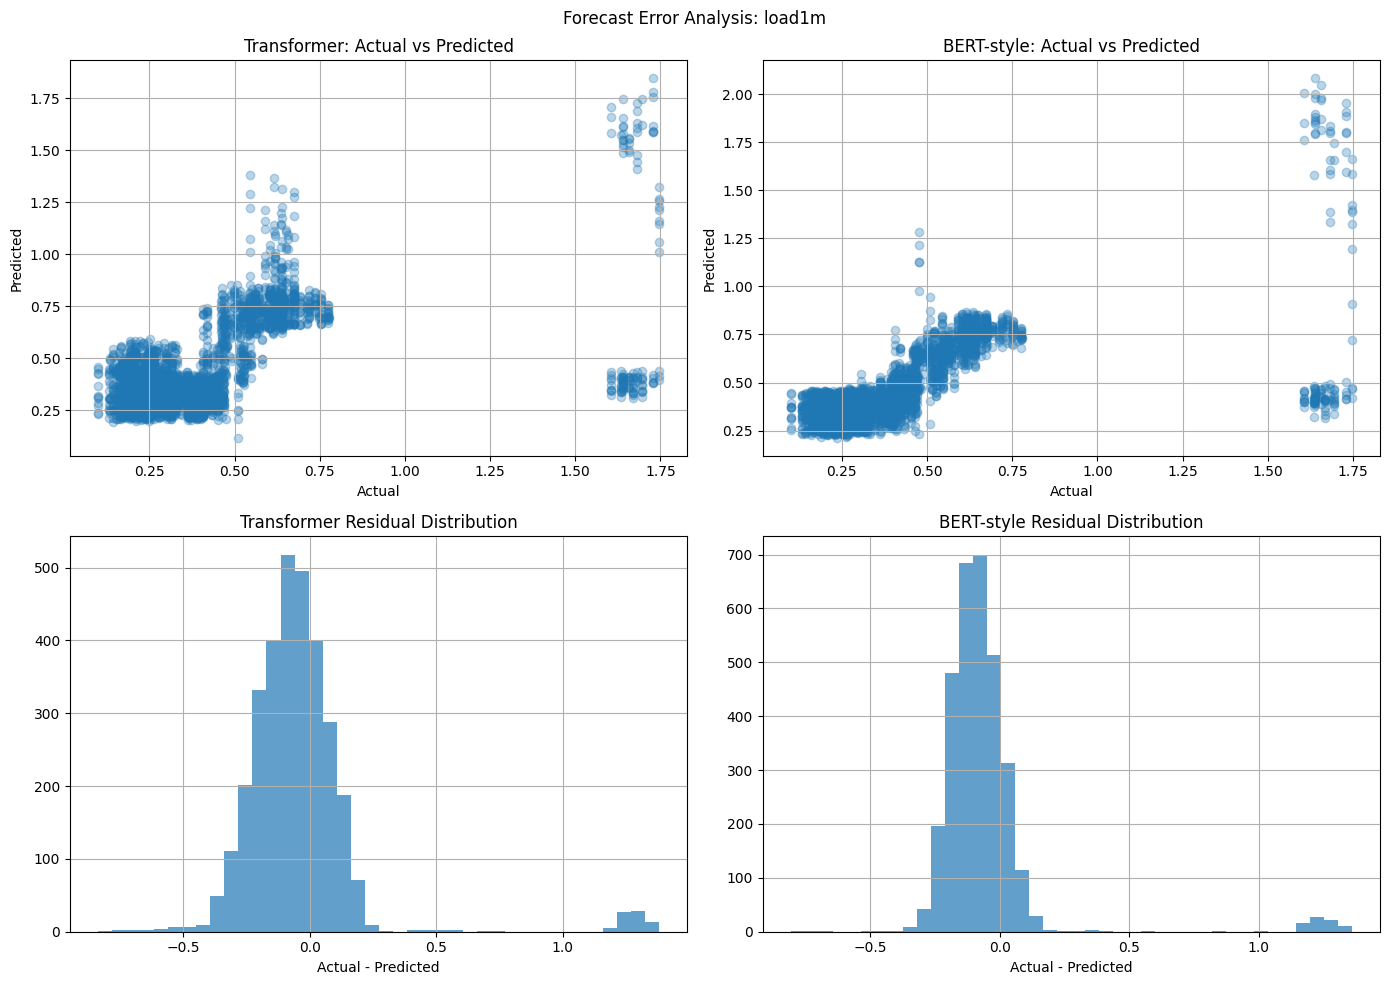

In [39]:
feature_name = "load1m"
feature_idx = features.index(feature_name)

actual_values = transformer_actual_original[:, :, feature_idx].flatten()
transformer_values = transformer_pred_original[:, :, feature_idx].flatten()
bert_values = bert_pred_original[:, :, feature_idx].flatten()

transformer_errors = actual_values - transformer_values
bert_errors = actual_values - bert_values

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].scatter(
    actual_values,
    transformer_values,
    alpha=0.3
)
axes[0, 0].set_title("Transformer: Actual vs Predicted")
axes[0, 0].set_xlabel("Actual")
axes[0, 0].set_ylabel("Predicted")
axes[0, 0].grid(True)

axes[0, 1].scatter(
    actual_values,
    bert_values,
    alpha=0.3
)
axes[0, 1].set_title("BERT-style: Actual vs Predicted")
axes[0, 1].set_xlabel("Actual")
axes[0, 1].set_ylabel("Predicted")
axes[0, 1].grid(True)

axes[1, 0].hist(
    transformer_errors,
    bins=40,
    alpha=0.7
)
axes[1, 0].set_title("Transformer Residual Distribution")
axes[1, 0].set_xlabel("Actual - Predicted")
axes[1, 0].grid(True)

axes[1, 1].hist(
    bert_errors,
    bins=40,
    alpha=0.7
)
axes[1, 1].set_title("BERT-style Residual Distribution")
axes[1, 1].set_xlabel("Actual - Predicted")
axes[1, 1].grid(True)

plt.suptitle(f"Forecast Error Analysis: {feature_name}")
plt.tight_layout()
plt.show()

In [40]:
import time

def benchmark_model(model, loader, model_name, warmup=10, repeats=100):
    model.eval()

    x, _ = next(iter(loader))
    x = x.to(DEVICE)

    with torch.no_grad():
        # Warm-up
        for _ in range(warmup):
            _ = model(x)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        for _ in range(repeats):
            _ = model(x)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start_time

    total_parameters = sum(
        parameter.numel() for parameter in model.parameters()
    )

    batch_latency_ms = (elapsed / repeats) * 1000
    sample_latency_ms = batch_latency_ms / x.size(0)

    return {
        "Model": model_name,
        "Parameters": total_parameters,
        "Batch Size": x.size(0),
        "Device": str(DEVICE),
        "Batch Latency (ms)": batch_latency_ms,
        "Latency per Sample (ms)": sample_latency_ms,
        "Throughput (samples/sec)": (
            x.size(0) / (elapsed / repeats)
        )
    }


performance_results = pd.DataFrame([
    benchmark_model(
        transformer_model,
        test_loader,
        "Transformer"
    ),
    benchmark_model(
        bert_model,
        test_loader,
        "BERT-style"
    )
])

display(performance_results)

,Model,Parameters,Batch Size,Device,Batch Latency (ms),Latency per Sample (ms),Throughput (samples/sec)
0,Transformer,915628,32,cpu,18.194838,0.568589,1758.740583
1,BERT-style,330704,32,cpu,7.347183,0.229599,4355.410774


In [41]:
horizon_comparison.to_csv(
    "horizon_wise_evaluation.csv",
    index=False
)

model_summary.to_csv(
    "model_evaluation_summary.csv",
    index=False
)

performance_results.to_csv(
    "model_performance_comparison.csv",
    index=False
)

print("Saved extended evaluation results.")

Saved extended evaluation results.


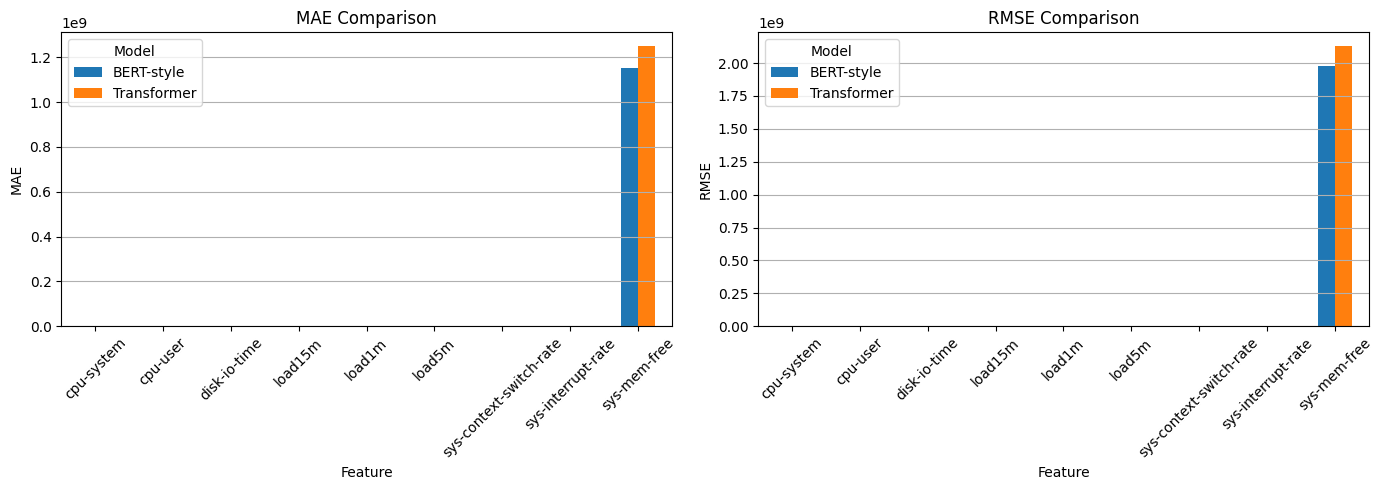

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for metric, ax in zip(["MAE", "RMSE"], axes):
    comparison.pivot(
        index="Feature",
        columns="Model",
        values=metric
    ).plot(kind="bar", ax=ax)

    ax.set_title(f"{metric} Comparison")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y")

plt.tight_layout()
plt.show()

In [43]:
comparison.to_csv(
    "model_comparison_results.csv",
    index=False
)

torch.save(
    {
        "model_state_dict": transformer_model.state_dict(),
        "features": features,
        "lookback": LOOKBACK,
        "horizon": HORIZON,
        "scaler_mean": scaler.mean_,
        "scaler_scale": scaler.scale_
    },
    "transformer_final.pt"
)

torch.save(
    {
        "model_state_dict": bert_model.state_dict(),
        "features": features,
        "lookback": LOOKBACK,
        "horizon": HORIZON,
        "patch_size": PATCH_SIZE,
        "scaler_mean": scaler.mean_,
        "scaler_scale": scaler.scale_
    },
    "bert_final.pt"
)

print("Saved both models and comparison results.")

Saved both models and comparison results.


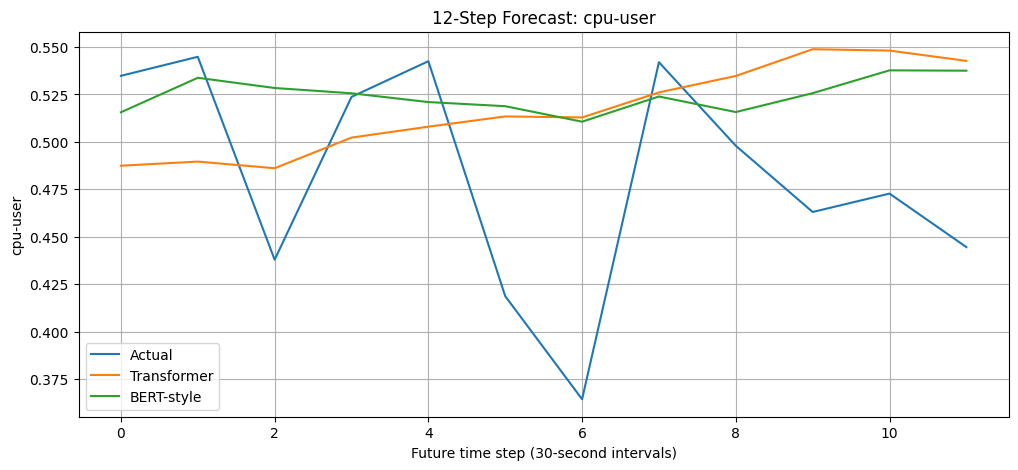

In [44]:
feature_name = "cpu-user"
feature_index = features.index(feature_name)

sample_index = 0

plt.figure(figsize=(12, 5))

plt.plot(
    transformer_actual_original[sample_index, :, feature_index],
    label="Actual"
)

plt.plot(
    transformer_pred_original[sample_index, :, feature_index],
    label="Transformer"
)

plt.plot(
    bert_pred_original[sample_index, :, feature_index],
    label="BERT-style"
)

plt.title(f"12-Step Forecast: {feature_name}")
plt.xlabel("Future time step (30-second intervals)")
plt.ylabel(feature_name)
plt.legend()
plt.grid(True)
plt.show()